In [1]:
#importing libraries:
import pandas as pd 
import numpy as np 

import matplotlib.pyplot as plt 
import seaborn as sns 

In [2]:
#loding the dataset 
df = pd.read_csv("S:/new datasets/predictive_maintenance_v3.csv")
df

,timestamp,machine_id,machine_type,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm,operating_mode,hours_since_maintenance,ambient_temp,rul_hours,failure_within_24h,failure_type,estimated_repair_cost
0,2024-01-01 00:00:00,1,CNC,0.81,49.51,5.10,23.6,860.9,idle,273.80,13.9,61.00,0,none,0
1,2024-01-01 00:03:00,1,CNC,0.75,40.58,5.30,23.6,899.6,idle,273.85,10.2,60.95,0,none,0
2,2024-01-01 00:21:00,1,CNC,0.71,49.70,NaN,21.3,862.7,idle,274.15,13.6,60.65,0,none,0
3,2024-01-01 00:45:00,1,CNC,0.76,43.04,4.79,22.6,870.4,idle,274.55,13.4,60.25,0,none,0
4,2024-01-01 00:54:00,1,CNC,0.88,41.39,4.44,22.2,881.9,idle,274.70,10.8,60.10,0,none,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24037,2024-01-14 22:17:56,20,Robotic Arm,0.98,37.18,5.27,45.0,361.8,normal,163.43,10.2,0.50,0,none,0
24038,2024-01-14 22:41:56,20,Robotic Arm,0.45,33.90,2.21,18.9,159.5,idle,163.83,11.0,0.50,0,none,0
24039,2024-01-14 22:58:56,20,Robotic Arm,0.40,29.15,2.29,19.0,159.5,idle,164.12,16.2,0.50,0,none,0
24040,2024-01-14 23:23:56,20,Robotic Arm,0.45,31.47,2.45,18.0,151.4,idle,164.53,16.7,0.50,0,none,0


In [3]:
#intial inspections: 
# First 5 records :
df.head()


,timestamp,machine_id,machine_type,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm,operating_mode,hours_since_maintenance,ambient_temp,rul_hours,failure_within_24h,failure_type,estimated_repair_cost
0,2024-01-01 00:00:00,1,CNC,0.81,49.51,5.10,23.6,860.9,idle,273.80,13.9,61.00,0,none,0
1,2024-01-01 00:03:00,1,CNC,0.75,40.58,5.30,23.6,899.6,idle,273.85,10.2,60.95,0,none,0
2,2024-01-01 00:21:00,1,CNC,0.71,49.70,NaN,21.3,862.7,idle,274.15,13.6,60.65,0,none,0
3,2024-01-01 00:45:00,1,CNC,0.76,43.04,4.79,22.6,870.4,idle,274.55,13.4,60.25,0,none,0
4,2024-01-01 00:54:00,1,CNC,0.88,41.39,4.44,22.2,881.9,idle,274.70,10.8,60.10,0,none,0


In [4]:
# last 5 records : 
df.tail()


,timestamp,machine_id,machine_type,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm,operating_mode,hours_since_maintenance,ambient_temp,rul_hours,failure_within_24h,failure_type,estimated_repair_cost
24037,2024-01-14 22:17:56,20,Robotic Arm,0.98,37.18,5.27,45.0,361.8,normal,163.43,10.2,0.5,0,none,0
24038,2024-01-14 22:41:56,20,Robotic Arm,0.45,33.90,2.21,18.9,159.5,idle,163.83,11.0,0.5,0,none,0
24039,2024-01-14 22:58:56,20,Robotic Arm,0.40,29.15,2.29,19.0,159.5,idle,164.12,16.2,0.5,0,none,0
24040,2024-01-14 23:23:56,20,Robotic Arm,0.45,31.47,2.45,18.0,151.4,idle,164.53,16.7,0.5,0,none,0
24041,2024-01-14 23:52:56,20,Robotic Arm,0.44,33.73,2.25,14.8,153.4,idle,165.02,9.2,0.5,0,none,0


In [5]:
#column names: 
df.columns

Index(['timestamp', 'machine_id', 'machine_type', 'vibration_rms',
       'temperature_motor', 'current_phase_avg', 'pressure_level', 'rpm',
       'operating_mode', 'hours_since_maintenance', 'ambient_temp',
       'rul_hours', 'failure_within_24h', 'failure_type',
       'estimated_repair_cost'],
      dtype='str')

In [6]:
#data types and non-null counts: 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 24042 entries, 0 to 24041
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   timestamp                24042 non-null  str    
 1   machine_id               24042 non-null  int64  
 2   machine_type             24042 non-null  str    
 3   vibration_rms            23042 non-null  float64
 4   temperature_motor        23208 non-null  float64
 5   current_phase_avg        23311 non-null  float64
 6   pressure_level           23118 non-null  float64
 7   rpm                      23509 non-null  float64
 8   operating_mode           24042 non-null  str    
 9   hours_since_maintenance  24042 non-null  float64
 10  ambient_temp             24042 non-null  float64
 11  rul_hours                24042 non-null  float64
 12  failure_within_24h       24042 non-null  int64  
 13  failure_type             24042 non-null  str    
 14  estimated_repair_cost    24042 no

In [7]:
#statistical summary: 
df.describe()

,machine_id,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm,hours_since_maintenance,ambient_temp,rul_hours,failure_within_24h,estimated_repair_cost
count,24042.000000,23042.000000,23208.000000,23311.000000,23118.000000,23509.000000,24042.000000,24042.000000,24042.000000,24042.000000,24042.000000
mean,10.505033,1.623667,51.404295,8.823829,59.012233,1144.849317,172.630624,12.996398,27.812510,0.148074,608.870144
std,5.746455,1.081061,12.519279,5.366391,38.723271,912.670971,150.722469,2.883994,26.393801,0.355181,1566.793887
min,1.000000,0.350000,28.000000,2.200000,10.100000,124.100000,0.000000,8.000000,0.500000,0.000000,0.000000
25%,6.000000,0.820000,42.610000,4.630000,22.700000,489.400000,42.870000,10.500000,0.500000,0.000000,0.000000
50%,10.000000,1.270000,50.060000,6.430000,46.300000,856.000000,121.610000,13.000000,22.570000,0.000000,0.000000
75%,15.000000,2.270000,59.962500,13.120000,94.700000,1676.000000,295.575000,15.500000,46.410000,0.000000,0.000000
max,20.000000,10.000000,95.000000,35.000000,206.500000,4098.800000,575.630000,18.000000,98.340000,1.000000,7995.000000


In [8]:
#sample records: 
df.sample(10)

,timestamp,machine_id,machine_type,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm,operating_mode,hours_since_maintenance,ambient_temp,rul_hours,failure_within_24h,failure_type,estimated_repair_cost
10310,2024-01-08 13:31:00,9,Pump,2.09,66.88,11.00,101.8,1350.0,normal,390.78,13.8,0.50,0,none,0
4706,2024-01-01 03:07:00,5,CNC,1.80,64.52,11.01,86.8,2832.7,normal,76.90,14.7,64.89,0,none,0
8364,2024-01-14 10:45:11,7,Pump,1.93,50.80,11.08,124.3,1319.5,normal,69.83,16.2,12.30,0,none,0
10507,2024-01-10 18:16:00,9,Pump,2.07,62.75,12.54,127.5,1257.3,normal,443.53,17.4,36.22,0,none,0
5340,2024-01-08 13:50:08,5,CNC,0.78,41.27,4.99,21.4,851.3,idle,72.00,11.4,11.48,0,none,0
14290,2024-01-13 19:34:36,12,Compressor,2.39,NaN,15.42,116.8,1782.2,normal,57.67,17.4,35.84,0,none,0
6774,2024-01-10 02:02:02,6,Pump,0.54,37.62,3.70,NaN,519.2,idle,138.80,13.1,0.50,0,none,0
19259,2024-01-14 22:55:38,16,Robotic Arm,0.44,31.32,2.33,19.4,148.9,idle,111.42,10.0,0.50,0,none,0
19857,2024-01-08 14:01:38,17,Robotic Arm,0.90,47.49,NaN,46.1,363.8,normal,56.53,11.3,22.39,0,none,0
15966,2024-01-05 03:22:00,14,Compressor,0.92,51.02,6.31,49.2,766.9,idle,348.23,13.9,0.50,0,none,0


In [9]:
#index information
df.index

RangeIndex(start=0, stop=24042, step=1)

In [10]:
#missing value analysis: 

df.isnull().sum()


timestamp                     0
machine_id                    0
machine_type                  0
vibration_rms              1000
temperature_motor           834
current_phase_avg           731
pressure_level              924
rpm                         533
operating_mode                0
hours_since_maintenance       0
ambient_temp                  0
rul_hours                     0
failure_within_24h            0
failure_type                  0
estimated_repair_cost         0
dtype: int64

In [11]:
#missing value percentage:
(df.isnull().sum()/len(df)*100).round(2)

timestamp                  0.00
machine_id                 0.00
machine_type               0.00
vibration_rms              4.16
temperature_motor          3.47
current_phase_avg          3.04
pressure_level             3.84
rpm                        2.22
operating_mode             0.00
hours_since_maintenance    0.00
ambient_temp               0.00
rul_hours                  0.00
failure_within_24h         0.00
failure_type               0.00
estimated_repair_cost      0.00
dtype: float64

In [12]:
#proper summary table 
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
]

missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)

,Missing_Count,Missing_Percentage
vibration_rms,1000,4.16
pressure_level,924,3.84
temperature_motor,834,3.47
current_phase_avg,731,3.04
rpm,533,2.22


In [13]:
#investigate missing values by machine type: 
df.groupby("machine_type")["temperature_motor"].apply(
    lambda x: x.isnull().sum()
)

machine_type
CNC            189
Compressor     218
Pump           221
Robotic Arm    206
Name: temperature_motor, dtype: int64

In [14]:
#percentage missing : 
df.groupby("machine_type")["temperature_motor"].apply(
    lambda x: (x.isnull().mean() * 100).round(2)
)

machine_type
CNC            3.18
Compressor     3.64
Pump           3.61
Robotic Arm    3.43
Name: temperature_motor, dtype: float64

In [15]:
# Missing values by machine type
missing_by_type = df.groupby("machine_type")[
    "temperature_motor"
].apply(
    lambda x: (x.isnull().mean() * 100).round(2)
)

missing_by_type

machine_type
CNC            3.18
Compressor     3.64
Pump           3.61
Robotic Arm    3.43
Name: temperature_motor, dtype: float64

In [16]:
#checking all five columns:
missing_by_type = df.groupby("machine_type").apply(
    lambda group: group.isnull().mean() * 100,
    include_groups=False
)

missing_by_type[
    ["vibration_rms", "temperature_motor", "current_phase_avg",
     "pressure_level", "rpm"]
].round(2)

,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm
machine_type,,,,,
CNC,4.04,3.18,2.59,3.57,2.09
Compressor,4.07,3.64,3.26,4.06,2.32
Pump,4.22,3.61,2.98,3.50,2.29
Robotic Arm,4.30,3.43,3.33,4.25,2.17


In [17]:
# missing values by operating mde:
missing_by_mode = df.groupby("operating_mode").apply(
    lambda group: group.isnull().mean() * 100,
    include_groups=False
)

missing_by_mode[
    ["vibration_rms", "temperature_motor", "current_phase_avg",
     "pressure_level", "rpm"]
].round(2)

,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm
operating_mode,,,,,
idle,4.23,3.34,3.01,3.84,2.25
normal,4.21,3.49,3.14,3.85,2.06
peak,3.29,4.20,2.52,3.81,3.17


In [18]:
#missing percentage by machine 
missing_by_machine = df.groupby("machine_id").apply(
    lambda group: group.isnull().mean() * 100,
    include_groups=False
)

missing_by_machine[
    ["vibration_rms", "temperature_motor", "current_phase_avg",
     "pressure_level", "rpm"]
].round(2)

,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm
machine_id,,,,,
1,4.03,3.10,3.02,4.11,2.18
2,3.66,2.44,2.18,3.32,2.53
3,4.93,2.63,2.30,3.53,2.22
4,3.94,4.29,2.37,3.59,1.14
5,3.63,3.47,3.06,3.31,2.34
6,3.54,3.47,3.47,4.08,1.77
7,4.32,3.81,3.31,3.14,1.69
8,4.12,3.22,2.06,3.30,2.39
9,4.40,3.52,2.88,3.20,2.48


In [19]:
df['timestamp'].dtype

<StringDtype(na_value=nan)>

In [20]:
df['timestamp']=pd.to_datetime(df['timestamp'])

In [21]:
#checking missing values by date:
missing_by_date = df.groupby(
    df["timestamp"].dt.date
).apply(
    lambda group: group.isnull().mean() * 100,
    include_groups=False
)

missing_by_date[
    ["vibration_rms", "temperature_motor", "current_phase_avg",
     "pressure_level", "rpm"]
].round(2)

,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm
timestamp,,,,,
2024-01-01,4.35,3.52,2.81,3.80,2.42
2024-01-02,3.39,3.16,3.22,2.88,2.54
2024-01-03,4.74,3.22,2.37,3.71,2.92
2024-01-04,3.71,3.21,3.15,4.14,2.22
2024-01-05,4.01,3.96,3.37,4.60,2.09
2024-01-06,4.42,4.02,3.10,3.73,1.61
2024-01-07,4.79,3.55,3.31,4.43,2.07
2024-01-08,3.64,3.29,2.89,4.27,1.56
2024-01-09,3.62,3.85,3.20,4.03,2.49


In [22]:
#missingness by hour:
missing_by_hour = df.groupby(
    df["timestamp"].dt.hour
).apply(
    lambda group: group.isnull().mean() * 100,
    include_groups=False
)

missing_by_hour[
    ["vibration_rms", "temperature_motor", "current_phase_avg",
     "pressure_level", "rpm"]
].round(2)

,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm
timestamp,,,,,
0,3.86,2.90,2.90,2.80,2.90
1,3.88,2.96,3.47,4.59,1.84
2,4.62,3.21,4.02,4.12,1.61
3,4.36,3.37,2.97,3.17,2.08
4,3.23,3.54,2.19,3.64,2.19
5,3.33,3.33,2.53,4.34,2.12
6,3.42,4.82,2.01,3.12,1.91
7,4.00,3.08,2.56,4.10,1.64
8,5.81,3.94,3.44,3.84,2.95


In [38]:
(df.isnull().sum().sum()/len(df)*100).round(2)

np.float64(16.73)

In [23]:
missing_flags = df[
    ["vibration_rms", "temperature_motor", "current_phase_avg",
     "pressure_level", "rpm"]
].isnull()

missing_flags.corr().round(2)

,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm
vibration_rms,1.00,0.10,0.09,0.09,0.12
temperature_motor,0.10,1.00,0.09,0.09,0.13
current_phase_avg,0.09,0.09,1.00,0.07,0.12
pressure_level,0.09,0.09,0.07,1.00,0.10
rpm,0.12,0.13,0.12,0.10,1.00


In [24]:
#checking skewness before going further 
df[
    ["vibration_rms", "temperature_motor", "current_phase_avg",
     "pressure_level", "rpm"]
].skew().round(2)

vibration_rms        1.48
temperature_motor    0.50
current_phase_avg    0.84
pressure_level       0.67
rpm                  1.11
dtype: float64

In [25]:
df_clean = df.copy()

In [26]:
df

,timestamp,machine_id,machine_type,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm,operating_mode,hours_since_maintenance,ambient_temp,rul_hours,failure_within_24h,failure_type,estimated_repair_cost
0,2024-01-01 00:00:00,1,CNC,0.81,49.51,5.10,23.6,860.9,idle,273.80,13.9,61.00,0,none,0
1,2024-01-01 00:03:00,1,CNC,0.75,40.58,5.30,23.6,899.6,idle,273.85,10.2,60.95,0,none,0
2,2024-01-01 00:21:00,1,CNC,0.71,49.70,NaN,21.3,862.7,idle,274.15,13.6,60.65,0,none,0
3,2024-01-01 00:45:00,1,CNC,0.76,43.04,4.79,22.6,870.4,idle,274.55,13.4,60.25,0,none,0
4,2024-01-01 00:54:00,1,CNC,0.88,41.39,4.44,22.2,881.9,idle,274.70,10.8,60.10,0,none,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24037,2024-01-14 22:17:56,20,Robotic Arm,0.98,37.18,5.27,45.0,361.8,normal,163.43,10.2,0.50,0,none,0
24038,2024-01-14 22:41:56,20,Robotic Arm,0.45,33.90,2.21,18.9,159.5,idle,163.83,11.0,0.50,0,none,0
24039,2024-01-14 22:58:56,20,Robotic Arm,0.40,29.15,2.29,19.0,159.5,idle,164.12,16.2,0.50,0,none,0
24040,2024-01-14 23:23:56,20,Robotic Arm,0.45,31.47,2.45,18.0,151.4,idle,164.53,16.7,0.50,0,none,0


In [29]:
len(df.groupby('nunique'))

4

In [39]:
# #missing value treatment: 
# How can we handle missing sensor readings without unnecessarily deleting records?

sensor_columns = [
    "vibration_rms",
    "temperature_motor",
    "current_phase_avg",
    "pressure_level",
    "rpm"
]

for col in sensor_columns:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )




In [40]:
#varifying the result:
df_clean[sensor_columns].isnull().sum()

vibration_rms        0
temperature_motor    0
current_phase_avg    0
pressure_level       0
rpm                  0
dtype: int64

In [41]:
df_clean.isnull().sum()

timestamp                  0
machine_id                 0
machine_type               0
vibration_rms              0
temperature_motor          0
current_phase_avg          0
pressure_level             0
rpm                        0
operating_mode             0
hours_since_maintenance    0
ambient_temp               0
rul_hours                  0
failure_within_24h         0
failure_type               0
estimated_repair_cost      0
dtype: int64

In [ ]:
# Analysis 02: Missing Value Treatment
# Missing values in five sensor columns were replaced
# using their respective median values.
# Verified that all five columns now contain zero missing values.

In [43]:
# #duplicate record analysis: 
# does our dataset contain any duplicate records?
df_clean.duplicated().sum()


np.int64(0)

In [ ]:
# Analysis 03: Duplicate Record Analysis
# Checked for duplicate rows using duplicated().
# No duplicate records were found.
# Therefore, no rows were removed.

In [44]:
# Analysis 04: Data Type Validation
# Business Question: Are all columns stored using appropriate data types for analysis?
#check data types: 
df_clean.dtypes

timestamp                  datetime64[us]
machine_id                          int64
machine_type                          str
vibration_rms                     float64
temperature_motor                 float64
current_phase_avg                 float64
pressure_level                    float64
rpm                               float64
operating_mode                        str
hours_since_maintenance           float64
ambient_temp                      float64
rul_hours                         float64
failure_within_24h                  int64
failure_type                          str
estimated_repair_cost               int64
dtype: object

In [ ]:
# Analysis 04: Data Type Validation
# Checked data types of all 15 columns.
# All columns have appropriate data types.
# No further conversion was required.

In [45]:
# Analysis 05: Invalid Value Analysis
# Business Question: Are there any invalid or impossible values in our dataset?

df_clean.describe().loc["min"]

timestamp                  2024-01-01 00:00:00
machine_id                                 1.0
vibration_rms                             0.35
temperature_motor                         28.0
current_phase_avg                          2.2
pressure_level                            10.1
rpm                                      124.1
hours_since_maintenance                    0.0
ambient_temp                               8.0
rul_hours                                  0.5
failure_within_24h                         0.0
estimated_repair_cost                      0.0
Name: min, dtype: object

In [46]:
#checking maximum values: 
df_clean.describe().loc["max"]

timestamp                  2024-01-14 23:59:38
machine_id                                20.0
vibration_rms                             10.0
temperature_motor                         95.0
current_phase_avg                         35.0
pressure_level                           206.5
rpm                                     4098.8
hours_since_maintenance                 575.63
ambient_temp                              18.0
rul_hours                                98.34
failure_within_24h                         1.0
estimated_repair_cost                   7995.0
Name: max, dtype: object

In [47]:
# Check categorical values
# Business Question: Do our categorical columns contain unexpected or inconsistent categories?

categorical_columns = [
    "machine_type",
    "operating_mode",
    "failure_type"
]

for col in categorical_columns:
    print(f"\n{col}")
    print(df_clean[col].value_counts())



machine_type
machine_type
Pump           6114
Robotic Arm    6003
Compressor     5988
CNC            5937
Name: count, dtype: int64

operating_mode
operating_mode
normal    11632
idle      10862
peak       1548
Name: count, dtype: int64

failure_type
failure_type
none              20482
bearing            1117
motor_overheat     1060
hydraulic           728
electrical          655
Name: count, dtype: int64


In [ ]:
# Analysis 05: Invalid Value Analysis
# Checked minimum and maximum numerical values.
# No obviously invalid values were identified.
# Checked categorical columns and found consistent categories.
# No records were removed.

In [48]:
print("Dataset Shape:", df_clean.shape)

print("\nTotal Missing Values:", df_clean.isnull().sum().sum())

print("\nTotal Duplicate Rows:", df_clean.duplicated().sum())

Dataset Shape: (24042, 15)

Total Missing Values: 0

Total Duplicate Rows: 0


In [49]:
# #EDA:
# How many records are available for each type of machine?
df_clean["machine_type"].value_counts()

machine_type
Pump           6114
Robotic Arm    6003
Compressor     5988
CNC            5937
Name: count, dtype: int64

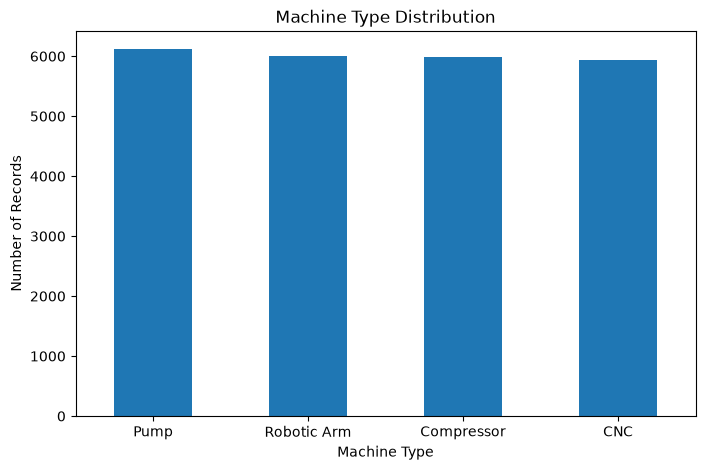

In [50]:
# Machine Type Distribution
machine_counts = df_clean["machine_type"].value_counts()

machine_counts.plot(
    kind="bar",
    title="Machine Type Distribution",
    xlabel="Machine Type",
    ylabel="Number of Records",
    figsize=(8, 5)
)

plt.xticks(rotation=0)
plt.show()

In [ ]:
# Key findings:
# 1. Pump has the highest number of records (6,114).
# 2. Robotic Arm has 6,003 records.
# 3. Compressor has 5,988 records.
# 4. CNC has the lowest number of records (5,937).

In [52]:
# How many records belong to each machine operating mode?
df_clean["operating_mode"].value_counts()

operating_mode
normal    11632
idle      10862
peak       1548
Name: count, dtype: int64

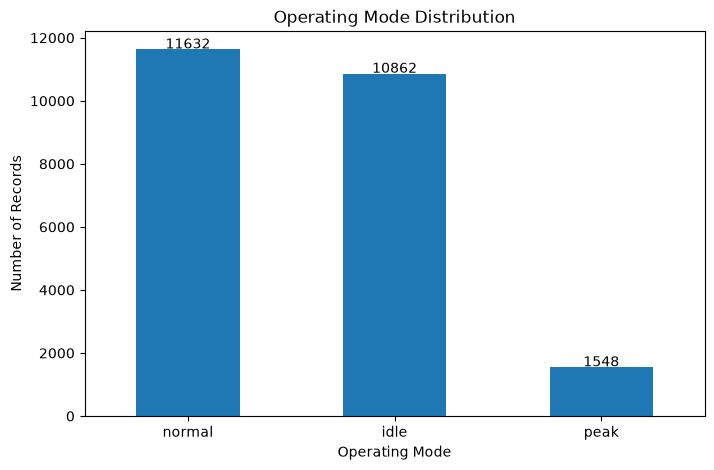

In [54]:
# Operating Mode Distribution
mode_counts = df_clean["operating_mode"].value_counts()

mode_counts.plot(
    kind="bar",
    title="Operating Mode Distribution",
    xlabel="Operating Mode",
    ylabel="Number of Records",
    figsize=(8, 5)
)

plt.xticks(rotation=0)

for i, value in enumerate(mode_counts):
    plt.text(i, value + 30, str(value), ha="center")

plt.show()

In [55]:
How many records have a failure recorded, and how many have no failure recorded?
df_clean["failure_within_24h"].value_counts()

failure_within_24h
0    20482
1     3560
Name: count, dtype: int64

In [56]:
df_clean["failure_within_24h"].value_counts(normalize=True).mul(100).round(2)

failure_within_24h
0    85.19
1    14.81
Name: proportion, dtype: float64

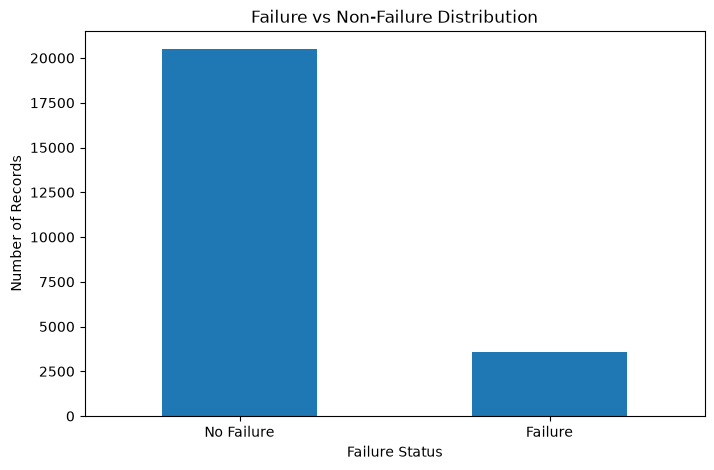

In [58]:
# Failure vs Non-Failure Distribution
failure_counts = df_clean["failure_within_24h"].value_counts()

failure_counts.index = ["No Failure", "Failure"]

failure_counts.plot(
    kind="bar",
    title="Failure vs Non-Failure Distribution",
    xlabel="Failure Status",
    ylabel="Number of Records",
    figsize=(8, 5)
)

plt.xticks(rotation=0)


plt.show()

In [59]:
# Which type of machine failure is recorded most frequently in our dataset?
df_clean["failure_type"].value_counts()

failure_type
none              20482
bearing            1117
motor_overheat     1060
hydraulic           728
electrical          655
Name: count, dtype: int64

In [60]:
#calculating percentage: 
failure_type_counts = df_clean.loc[
    df_clean["failure_type"] != "none",
    "failure_type"
].value_counts()

failure_type_percent = (
    failure_type_counts / failure_type_counts.sum()
) * 100

failure_type_percent.round(2)

failure_type
bearing           31.38
motor_overheat    29.78
hydraulic         20.45
electrical        18.40
Name: count, dtype: float64

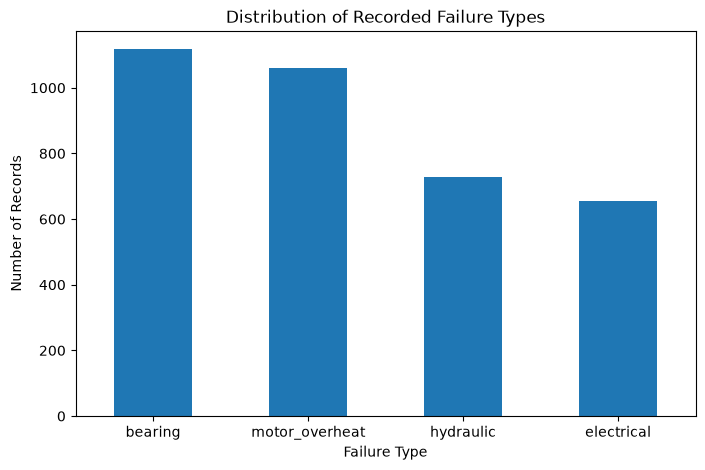

In [61]:
failure_type_counts.plot(
    kind="bar",
    figsize=(8, 5),
    title="Distribution of Recorded Failure Types",
    xlabel="Failure Type",
    ylabel="Number of Records"
)

plt.xticks(rotation=0)


plt.show()

In [64]:
# Which machine types have the highest number of records with a failure label?
failure_by_machine = df_clean.groupby(
    "machine_type"
)["failure_within_24h"].sum()

failure_by_machine

machine_type
CNC            834
Compressor     958
Pump           913
Robotic Arm    855
Name: failure_within_24h, dtype: int64

In [65]:
failure_percentage_by_machine = (
    df_clean.groupby("machine_type")["failure_within_24h"].mean() * 100
)

failure_percentage_by_machine.round(2)

machine_type
CNC            14.05
Compressor     16.00
Pump           14.93
Robotic Arm    14.24
Name: failure_within_24h, dtype: float64

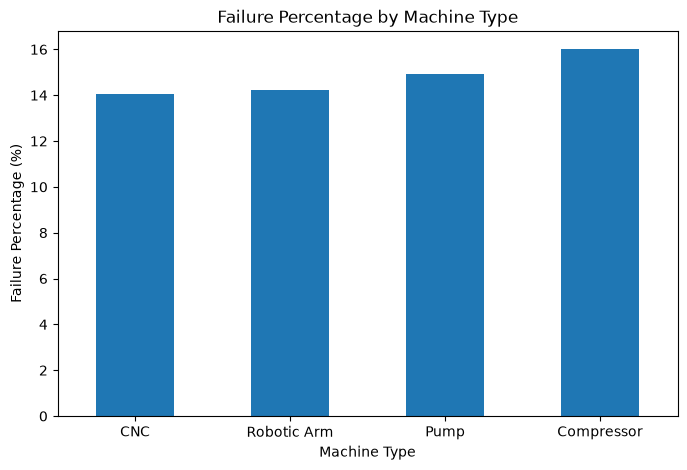

In [66]:
failure_percentage_by_machine.sort_values().plot(
    kind="bar",
    figsize=(8, 5),
    title="Failure Percentage by Machine Type",
    xlabel="Machine Type",
    ylabel="Failure Percentage (%)"
)

plt.xticks(rotation=0)


plt.show()

Key Insights:
- Compressor recorded the highest number of positive failure records (958).
- Compressor also had the highest positive failure percentage (16.00%).
- CNC had the lowest positive failure percentage (14.05%).
- The failure percentages across all four machine types were relatively close.

In [67]:
# During which operating mode are the most positive failure records observed?
failure_by_mode = df_clean.groupby(
    "operating_mode"
)["failure_within_24h"].sum()

failure_by_mode

operating_mode
idle      1574
normal    1738
peak       248
Name: failure_within_24h, dtype: int64

In [68]:
# failure percentage by operating mode
failure_percentage_by_mode = (
    df_clean.groupby("operating_mode")["failure_within_24h"].mean() * 100
)

failure_percentage_by_mode.round(2)

operating_mode
idle      14.49
normal    14.94
peak      16.02
Name: failure_within_24h, dtype: float64

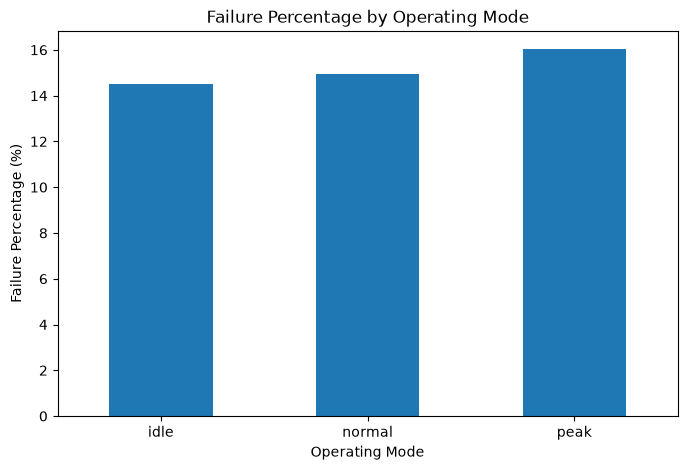

In [69]:
# Failure Percentage by Operating Mode
failure_percentage_by_mode.sort_values().plot(
    kind="bar",
    figsize=(8, 5),
    title="Failure Percentage by Operating Mode",
    xlabel="Operating Mode",
    ylabel="Failure Percentage (%)"
)

plt.xticks(rotation=0)



plt.show()

In [ ]:
# Key Insights:
# - Normal mode recorded the highest number of positive failure records (1,738).
# - Peak mode had the highest positive failure percentage (16.02%).
# - Idle mode had the lowest positive failure percentage (14.49%).
# - Although peak mode had fewer positive failure records, its failure percentage was higher than the other two modes.

In [70]:
# During which hours of the day are the most positive failure records observed?
failure_by_hour = df_clean.groupby(
    df_clean["timestamp"].dt.hour
)["failure_within_24h"].sum()

failure_by_hour

timestamp
0     145
1     145
2     149
3     155
4     145
5     144
6     150
7     138
8     154
9     151
10    150
11    141
12    147
13    156
14    147
15    163
16    150
17    138
18    152
19    139
20    143
21    152
22    156
23    150
Name: failure_within_24h, dtype: int64

In [71]:
print("Highest failure records:", failure_by_hour.max())
print("Hour with highest records:", failure_by_hour.idxmax())

print("Lowest failure records:", failure_by_hour.min())
print("Hour with lowest records:", failure_by_hour.idxmin())

Highest failure records: 163
Hour with highest records: 15
Lowest failure records: 138
Hour with lowest records: 7


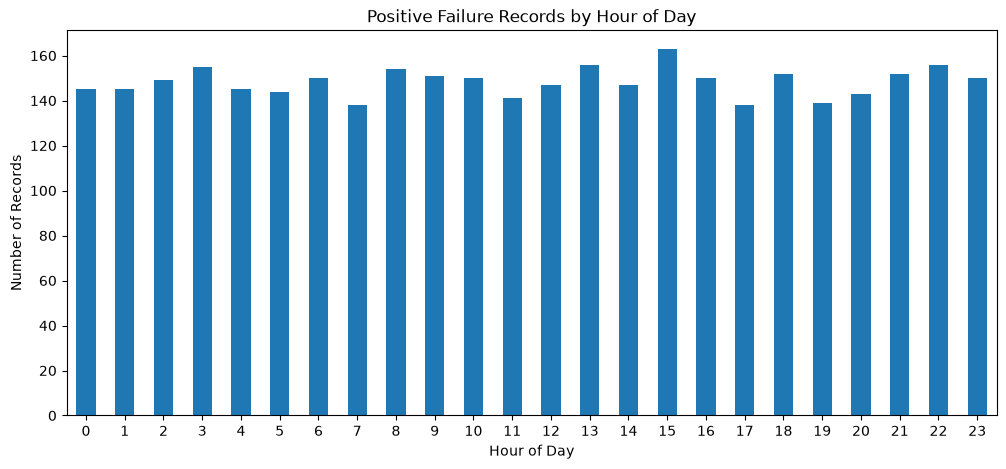

In [72]:
# Positive Failure Records by Hour of Day
failure_by_hour.plot(
    kind="bar",
    figsize=(12, 5),
    title="Positive Failure Records by Hour of Day",
    xlabel="Hour of Day",
    ylabel="Number of Records"
)

plt.xticks(rotation=0)
plt.show()

Key Insights:
- 3 PM recorded the highest number of positive failure records (163).
- 7 AM and 5 PM recorded the lowest counts (138 each).
- The hourly counts range from 138 to 163, showing relatively little variation.
- No strong hourly pattern is immediately visible from these counts.

In [73]:
# Which individual machines have the highest number of positive failure records?
failure_by_machine_id = df_clean.groupby(
    "machine_id"
)["failure_within_24h"].sum().sort_values(
    ascending=False
)

failure_by_machine_id

machine_id
13    287
7     275
10    275
4     263
19    262
20    241
11    215
1     187
3     183
15    182
12    182
17    177
8     175
2     108
6      98
5      93
14     92
9      90
16     89
18     86
Name: failure_within_24h, dtype: int64

Key observations:
- Machine 13 has the highest count (287).
- Machines 7 and 10 are tied at 275.
- Machine 18 has the lowest count (86).
- There is a noticeable difference between the highest and lowest machine counts.

In [74]:
# Calculate failure percentage by machine
failure_percentage_by_machine_id = (
    df_clean.groupby("machine_id")["failure_within_24h"].mean() * 100
).sort_values(ascending=False)

failure_percentage_by_machine_id.round(2)

machine_id
13    23.94
10    23.46
7     23.31
4     23.05
19    22.34
20    20.51
11    18.79
1     15.69
15    15.22
12    15.14
3     15.02
17    14.86
8     14.43
2      9.42
6      7.55
5      7.50
14     7.38
16     7.27
9      7.19
18     6.94
Name: failure_within_24h, dtype: float64

Key observations
1. Machine 13 has the highest positive failure percentage (23.94%).
2. Machines 10 and 7 follow closely.
3. Machine 18 has the lowest percentage (6.94%).
4. There is a noticeable difference between machines.

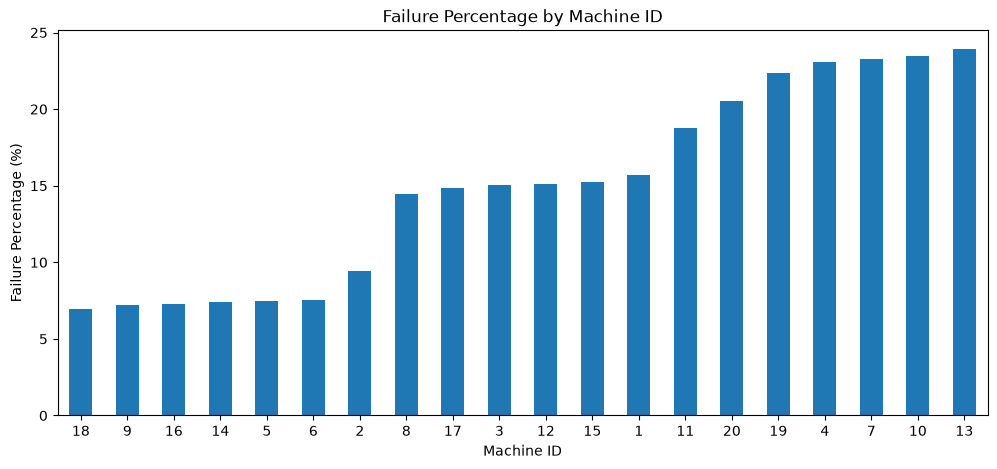

In [75]:
# Failure Percentage by Machine ID
failure_percentage_by_machine_id.sort_values().plot(
    kind="bar",
    figsize=(12, 5),
    title="Failure Percentage by Machine ID",
    xlabel="Machine ID",
    ylabel="Failure Percentage (%)"
)

plt.xticks(rotation=0)
plt.show()

Key Insights:
- Machine 13 recorded the highest number of positive failure records (287).
- Machine 13 also had the highest positive failure percentage (23.94%).
- Machines 10, 7, and 4 also showed comparatively high percentages.
- Machine 18 had the lowest positive failure percentage (6.94%).

In [76]:
# How are the machine sensor measurements distributed across the dataset?
# Calculate descriptive statistics
sensor_columns = [
    "vibration_rms",
    "temperature_motor",
    "current_phase_avg",
    "pressure_level",
    "rpm"
]

df_clean[sensor_columns].describe().round(2)

,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm
count,24042.00,24042.00,24042.00,24042.00,24042.00
mean,1.61,51.36,8.75,58.52,1138.45
std,1.06,12.30,5.30,38.05,903.50
min,0.35,28.00,2.20,10.10,124.10
25%,0.85,42.89,4.71,23.10,496.02
50%,1.27,50.06,6.43,46.30,856.00
75%,2.23,59.60,12.99,90.80,1667.88
max,10.00,95.00,35.00,206.50,4098.80


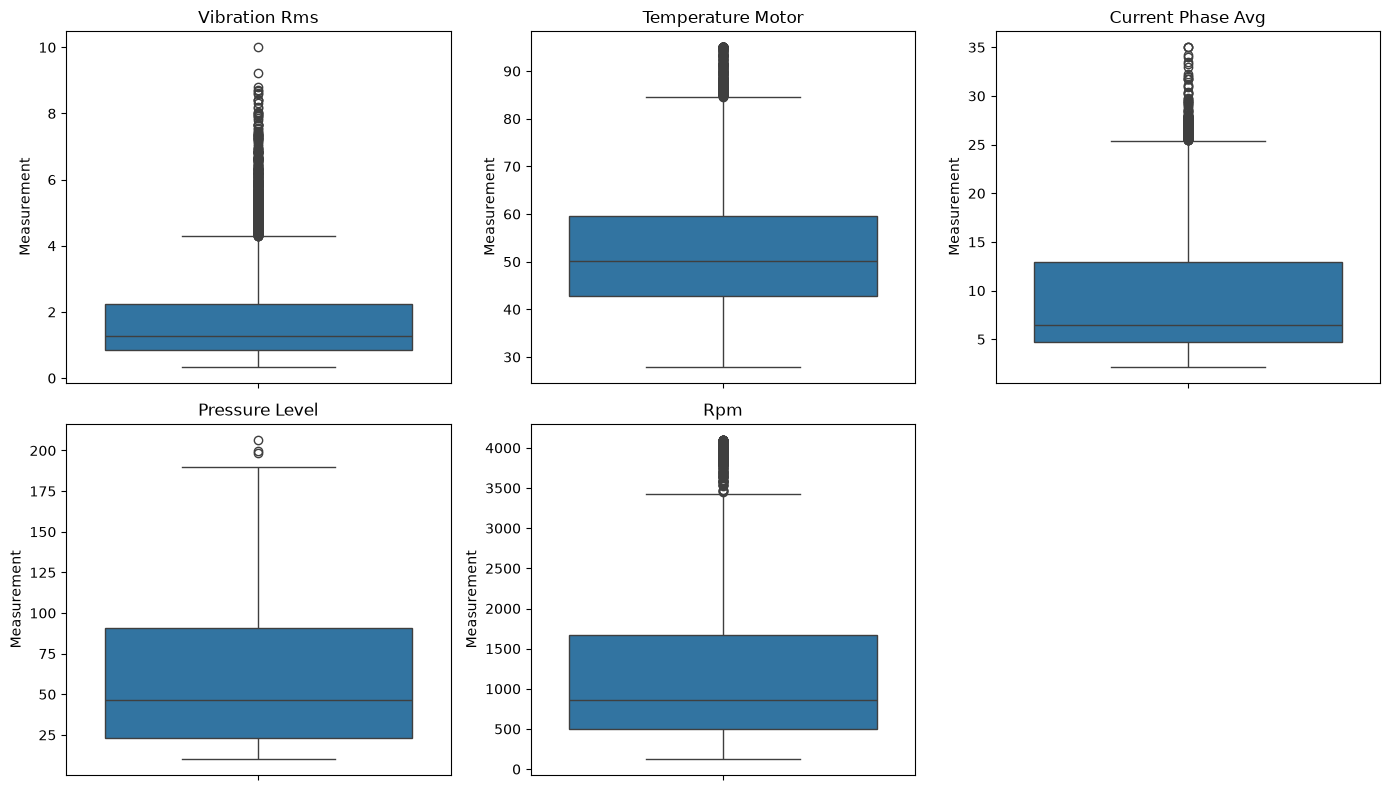

In [79]:
# Distribution and Spread of Machine Sensor Measurements
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for ax, col in zip(axes.flatten(), sensor_columns):
    sns.boxplot(data=df_clean, y=col, ax=ax)
    ax.set_title(col.replace("_", " ").title())
    ax.set_ylabel("Measurement")

# Remove the unused sixth plot
fig.delaxes(axes[1, 2])

plt.tight_layout()
plt.show()

Key Insights:
- The five sensor measurements show different distributions and levels of variation.
- Vibration RMS, current phase average, and RPM contain several potential upper outliers.
- Motor temperature measurements are more concentrated around the median.
- The boxplots help identify unusual observations that may require further investigation.

In [81]:
# # Statistics & Visualization.
# What is the average vibration measurement across all machine records?
(df_clean["vibration_rms"].mean()).round(2)

np.float64(1.61)

In [83]:
#median:median value of temperature_motor 
df_clean["temperature_motor"].median()

np.float64(50.06)

In [85]:
# How much do sensor measurements vary between their lowest and highest recorded values?
df_clean[sensor_columns].agg(["min", "max"])

,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm
min,0.35,28.0,2.2,10.1,124.1
max,10.00,95.0,35.0,206.5,4098.8


In [86]:
#range:difference between maximum and minimum
df_clean[sensor_columns].max() - df_clean[sensor_columns].min()

vibration_rms           9.65
temperature_motor      67.00
current_phase_avg      32.80
pressure_level        196.40
rpm                  3974.70
dtype: float64

Key Insight: The sensor measurements show different ranges of variation. RPM has the largest numerical range (3974.70), while vibration RMS has the smallest (9.65). These values describe the spread between minimum and maximum readings

In [87]:
# How are the middle 50% of sensor readings distributed?
df_clean[sensor_columns].describe().loc[
    ["25%", "50%", "75%"]
].round(2)

,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm
25%,0.85,42.89,4.71,23.1,496.02
50%,1.27,50.06,6.43,46.3,856.00
75%,2.23,59.60,12.99,90.8,1667.88


In [88]:
#iQR
Q1 = df_clean[sensor_columns].quantile(0.25)
Q3 = df_clean[sensor_columns].quantile(0.75)

IQR = Q3 - Q1

IQR.round(2)

vibration_rms           1.38
temperature_motor      16.71
current_phase_avg       8.28
pressure_level         67.70
rpm                  1171.85
dtype: float64

In [89]:
# Are there unusually low or high sensor readings in our manufacturing dataset?
Q1 = df_clean[sensor_columns].quantile(0.25)
Q3 = df_clean[sensor_columns].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - (1.5 * IQR)
upper_limit = Q3 + (1.5 * IQR)

outlier_limits = pd.DataFrame({
    "Lower Limit": lower_limit,
    "Upper Limit": upper_limit
})

outlier_limits.round(2)

,Lower Limit,Upper Limit
vibration_rms,-1.22,4.30
temperature_motor,17.82,84.66
current_phase_avg,-7.71,25.41
pressure_level,-78.45,192.35
rpm,-1261.75,3425.65


In [91]:
# Count potential outliers
outlier_counts = {}

for x in sensor_columns:
    count = (
        (df_clean[x] < lower_limit[x]) |
        (df_clean[x] > upper_limit[x])
    ).sum()

    outlier_counts[x] = count

pd.Series(outlier_counts, name="Potential Outliers")

vibration_rms        523
temperature_motor    270
current_phase_avg    181
pressure_level         3
rpm                  374
Name: Potential Outliers, dtype: int64

Key Insight: The IQR method identified 1,351 potential outlier readings across the five sensor measurements. Vibration RMS had the highest count (523), while pressure level had the lowest (3). These readings require further investigation before deciding whether they represent unusual but valid machine behaviour or data errors.

In [92]:
# Which sensor measurements have stronger relationships with one another?
correlation_matrix = df_clean[sensor_columns].corr()

correlation_matrix.round(2)

,vibration_rms,temperature_motor,current_phase_avg,pressure_level,rpm
vibration_rms,1.00,0.71,0.82,0.72,0.75
temperature_motor,0.71,1.00,0.76,0.69,0.61
current_phase_avg,0.82,0.76,1.00,0.85,0.78
pressure_level,0.72,0.69,0.85,1.00,0.60
rpm,0.75,0.61,0.78,0.60,1.00


Key Insight: All five sensor measurements show positive correlations. The strongest observed relationship is between current phase average and pressure level (0.85), while the weakest is between pressure level and RPM (0.60). These are statistical relationships and do not establish causation.

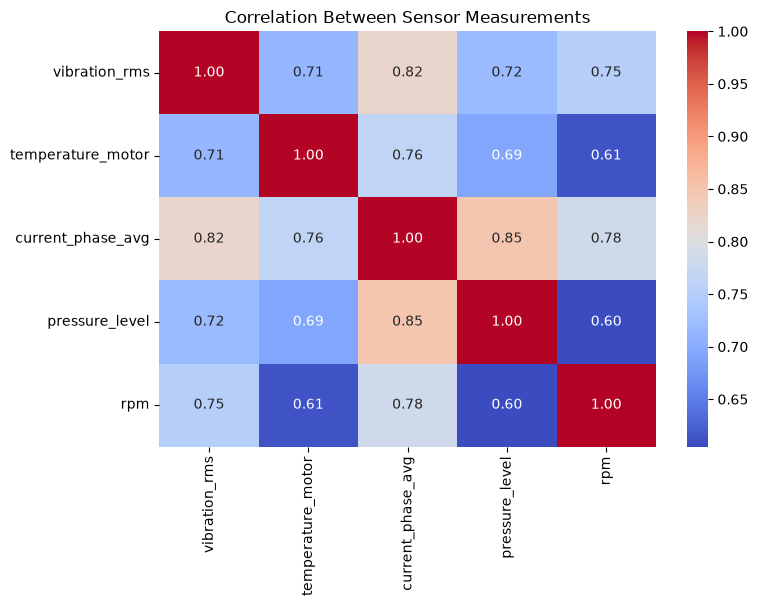

In [94]:
# Can we easily identify the strongest relationships between sensor measurements using a heatmap?
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.tight_layout()
plt.title("Correlation Between Sensor Measurements")
plt.show()

Notebook insight:
The correlation heatmap shows positive relationships among all five sensor measurements. Current phase average and pressure level have the strongest correlation (0.85). No negative correlations were observed.

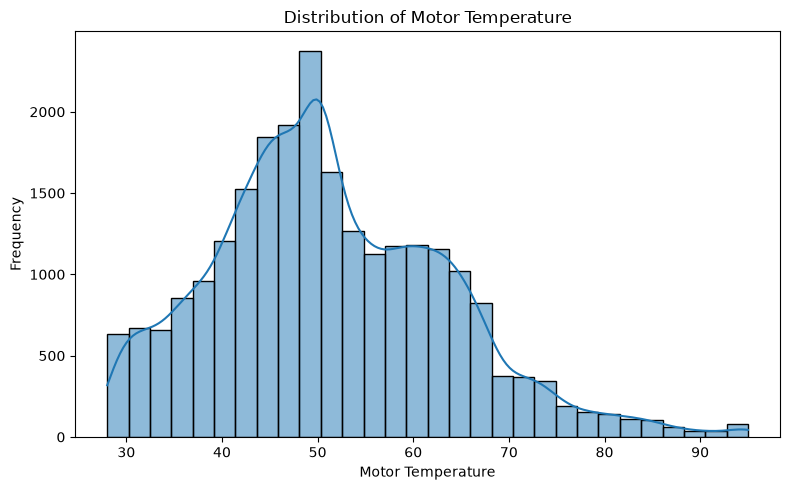

In [95]:
# How are sensor readings distributed across different value ranges?
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x="temperature_motor",
    bins=30,
    kde=True
)

plt.title("Distribution of Motor Temperature")
plt.xlabel("Motor Temperature")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

Key Insight: Most motor temperature readings are concentrated between approximately 40°C and 65°C, with the highest concentration around 48°C–50°C. The distribution is slightly right-skewed, with fewer observations at higher temperatures.

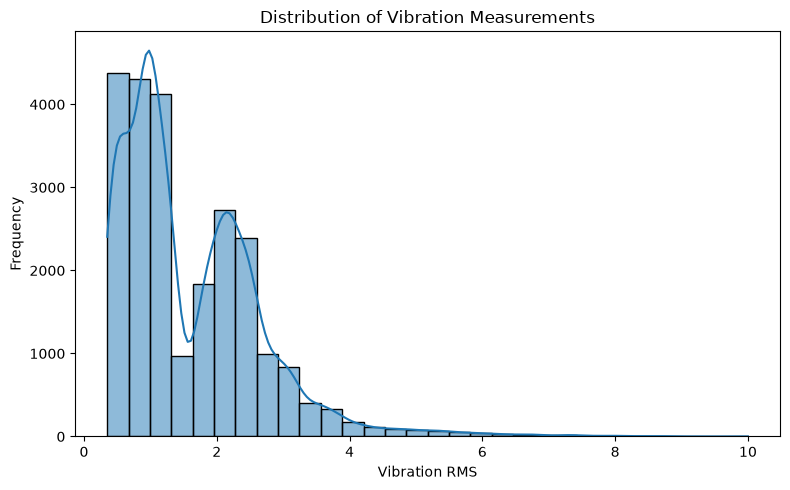

In [96]:
# How are vibration readings distributed across different value ranges?
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x="vibration_rms",
    bins=30,
    kde=True
)

plt.title("Distribution of Vibration Measurements")
plt.xlabel("Vibration RMS")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

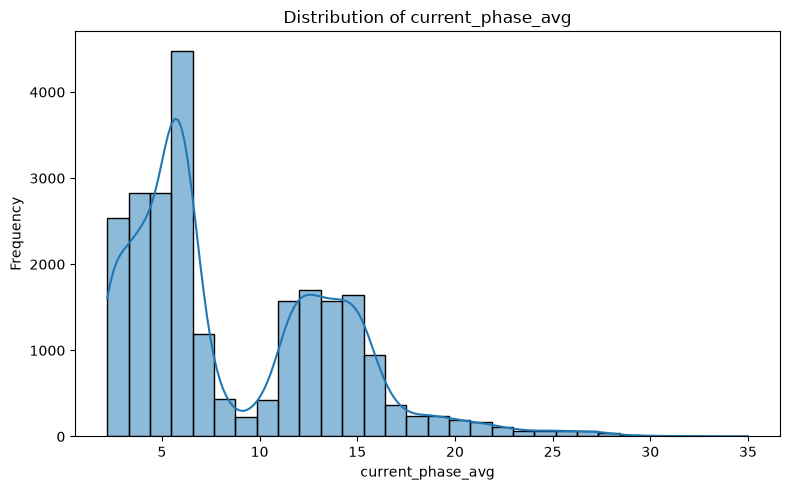

In [99]:
#how are value ranges distributed across different value ranges:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_clean,
    x="current_phase_avg",
    bins=30,
    kde=True
)

plt.title("Distribution of current_phase_avg")
plt.xlabel("current_phase_avg")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

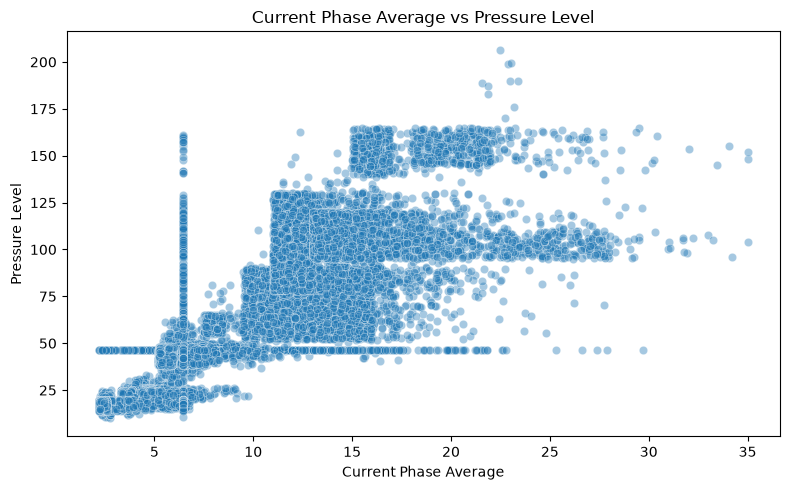

In [100]:
# #scatterplot:
# Do current phase average and pressure level move together?
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x="current_phase_avg",
    y="pressure_level",
    alpha=0.4
)

plt.title("Current Phase Average vs Pressure Level")
plt.xlabel("Current Phase Average")
plt.ylabel("Pressure Level")

plt.tight_layout()
plt.show()

Key Insight: The scatterplot shows a generally positive relationship between current phase average and pressure level. The observations form several clusters, and the correlation coefficient of 0.85 indicates a strong positive linear association. This relationship does not establish causation.

In [101]:
df_clean.to_csv("manufacturing_cleaned.csv", index=False)

In [102]:
import os

os.path.exists("manufacturing_cleaned.csv")

True